#Сбор данных с сайта

Выберем для парсинга форум сайта с рецептами say7.info, распарсим только интересующие темы (кроме алкогольных напитктов и рецептов для микроволновки и мультиварки).

In [27]:
!pip install datasketch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 2.9 MB/s eta 0:00:00


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from collections import Counter

pd.set_option('display.max_colwidth', 500)
from datasketch import MinHash, MinHashLSH
import time

In [ ]:
import requests
from bs4 import BeautifulSoup
import time
import csv
import re

BASE_URL = "https://forum.say7.info"
HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                  '(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
}

FORUM_URLS = [ 'https://forum.say7.info/forum66.html', 'https://forum.say7.info/forum64.html',
    "https://forum.say7.info/forum65.html",  'https://forum.say7.info/forum74.html',
    'https://forum.say7.info/forum76.html', 'https://forum.say7.info/forum70.html',
    'https://forum.say7.info/forum77.html', 'https://forum.say7.info/forum67.html',
    'https://forum.say7.info/forum68.html', 'https://forum.say7.info/forum73.html',
    'https://forum.say7.info/forum69.html', 'https://forum.say7.info/forum75.html',
    'https://forum.say7.info/forum111.html', 'https://forum.say7.info/forum71.html',
    'https://forum.say7.info/forum78.html', 'https://forum.say7.info/forum79.html',
    'https://forum.say7.info/forum45.html', 'https://forum.say7.info/forum50.html',
    'https://forum.say7.info/forum98.html'
]

MAX_TOPICS_PER_FORUM = 200
MAX_TOPIC_PAGES = 3
MAX_FORUM_PAGES = 10

SLEEP = 1.0
OUTPUT_FILE = "say7_forum_posts.csv"


def fix_url(href):
    if not href:
        return None
    if href.startswith('http'):
        return href
    return BASE_URL + '/' + href.lstrip('/')


def clean_text(text):
    if not text:
        return ""
    return re.sub(r'\s+', ' ', text).strip()


def get_topic_links(forum_url, max_pages=MAX_FORUM_PAGES):
    topic_links = {}
    for page in range(1, max_pages + 1):
        url = forum_url if page == 1 else f"{forum_url}?start={(page-1)*25}"
        try:
            resp = requests.get(url, headers=HEADERS, timeout=15)
            resp.encoding = 'windows-1251'
            resp.raise_for_status()
            soup = BeautifulSoup(resp.text, 'html.parser')

            links = soup.select('a.topictitle')
            found = 0
            for link in links:
                href = link.get('href')
                title = clean_text(link.get_text())
                if href and re.search(r'topic\d+', href):
                    full = fix_url(href)
                    if full and full not in topic_links:
                        topic_links[full] = title
                        found += 1
            print(f"  Раздел, стр. {page}: {found} новых тем")
            time.sleep(SLEEP)
        except Exception as e:
            print(f"  Ошибка: {e}")
            break
    return topic_links


def get_topic_posts(topic_url, topic_title, max_pages=MAX_TOPIC_PAGES):
    posts = []
    for page in range(1, max_pages + 1):
        url = topic_url if page == 1 else f"{topic_url}?start={(page-1)*10}"
        try:
            resp = requests.get(url, headers=HEADERS, timeout=15)
            resp.encoding = 'windows-1251'
            resp.raise_for_status()
            soup = BeautifulSoup(resp.text, 'html.parser')

            rows = soup.select('tr.rdmdt')
            if not rows:
                print(f"    Стр. {page}: сообщений нет, стоп")
                break

            page_posts = 0
            current_author = ""
            current_realname = ""
            current_date = ""

            for row in rows:
                nick_el = row.select_one('.pdtnm.nickname')
                if nick_el:
                    current_author = clean_text(nick_el.get_text())

                realname_el = row.select_one('.pdtav.photo div')
                if realname_el:
                    current_realname = clean_text(realname_el.get_text())

                date_el = row.select_one('.ipdata.taright')
                if date_el:
                    current_date = clean_text(date_el.get_text())

                postbody = row.select_one('div.postbody:not(.signature)')
                if postbody:
                    for sig in postbody.select('.signature'):
                        sig.decompose()

                    text = clean_text(postbody.get_text(separator=' ', strip=True))
                    if len(text) < 20:
                        continue

                    posts.append({
                        'topic_url': topic_url,
                        'topic_title': topic_title,
                        'author': current_author,
                        'real_name': current_realname,
                        'date': current_date,
                        'text': text,
                    })
                    page_posts += 1

            print(f"    Стр. {page}: {page_posts} сообщений")
            time.sleep(SLEEP)
        except Exception as e:
            print(f"    Ошибка: {e}")
            break
    return posts


def get_topic_title(soup):
    for el in soup.select('.icmp'):
        t = clean_text(el.get_text())
        if t:
            return t
    title = soup.select_one('title')
    return clean_text(title.get_text()) if title else ""


def main():
    all_posts = []
    for forum_url in FORUM_URLS:
        print(f"\n=== {forum_url} ===")
        topics = get_topic_links(forum_url)
        print(f"  Всего тем: {len(topics)}")

        for i, (topic_url, topic_title) in enumerate(list(topics.items())[:MAX_TOPICS_PER_FORUM]):
            print(f"\n  [{i+1}] {topic_title[:60]}")
            posts = get_topic_posts(topic_url, topic_title)
            all_posts.extend(posts)
            time.sleep(SLEEP)

    with open(OUTPUT_FILE, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=[
            'topic_url', 'topic_title', 'author', 'real_name', 'date', 'text'
        ])
        writer.writeheader()
        for post in all_posts:
            writer.writerow(post)

    print(f"\n✅ Сохранено {len(all_posts)} сообщений в {OUTPUT_FILE}")


if __name__ == "__main__":
    main()

Выходные данные были обрезаны до нескольких последних строк (5000).
    Стр. 2: 22 сообщений
    Стр. 3: 23 сообщений

  [158] Грибно-беконно-сливочный соус к пасте, некки
    Стр. 1: 3 сообщений
    Стр. 2: сообщений нет, стоп

  [159] Цацики с редисом
    Стр. 1: 3 сообщений
    Стр. 2: сообщений нет, стоп

  [160] Деревенский чатни (Old Farmhouse Chutney)
    Стр. 1: 18 сообщений
    Стр. 2: 9 сообщений
    Стр. 3: 2 сообщений

  [161] Маринад для курицы и индюшки
    Стр. 1: 12 сообщений
    Стр. 2: 2 сообщений
    Стр. 3: сообщений нет, стоп

  [162] Сливочно - маковый соус к сырникам
    Стр. 1: 5 сообщений
    Стр. 2: сообщений нет, стоп

  [163] Крем-шпинат
    Стр. 1: 24 сообщений
    Стр. 2: 23 сообщений
    Стр. 3: 22 сообщений

  [164] Соус Бешамель от Елены Молоховец
    Стр. 1: 25 сообщений
    Стр. 2: 15 сообщений
    Стр. 3: 5 сообщений

  [165] Соус «Сливочный»
    Стр. 1: 3 сообщений
    Стр. 2: сообщений нет, стоп

  [166] Английский клюквеннй соус
    Стр. 1: 3 сооб

UnicodeEncodeError: 'utf-8' codec can't encode characters in position 181-182: surrogates not allowed

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
shutil.copy('say7_forum_posts_SAVED.csv', '/content/drive/MyDrive/say7_forum_posts_SAVED.csv')
shutil.copy('say7_forum_posts.csv', '/content/drive/MyDrive/say7_forum_posts.csv')

# EDA

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [46]:
df = pd.read_csv('/content/drive/MyDrive/Agents_Course/say7_forum_posts_SAVED.csv')

In [47]:
df.columns

Index(['topic_url', 'topic_title', 'author', 'real_name', 'date', 'text'], dtype='object')

In [4]:
print(f'Размер датасета: {len(df)}')

Размер датасета: 160194


Мы скачали с форума как рецепты, так и комментарии к ним.

In [ ]:
df.head()

,topic_url,topic_title,author,real_name,date,text
0,https://forum.say7.info/topic105637.html,Салат «Свежий аккорд»,Д_И_ана,Ирина,10 Окт 2026 20:40,"Салат ""Свежий аккорд"" - легкий салат с гармоничным вкусом. Ингредиенты на две порции: Огурец --150 г Мякоть авокадо --100 г Сыр адыгейский несоленый --100 г Несладкий йогурт или нежирная сметана --40 г Оливковое масло 15 г Зелень свежая(петрушка)-2-3 веточки без стеблей Соль --1 щепотка (по вкусу) Пошаговое приготовление Подготовьте овощи и зелень. Огурец вымойте, очистите от шкурки, нарежьте мелкими кубиками. Авокадо разрежьте, удалите косточку, снимите кожуру и тоже нарежьте кубиками. Можн..."
1,https://forum.say7.info/topic105636.html,Салат Крабовый сон,Dosik,Маришка,10 Окт 2026 17:41,"Салат Крабовый сон. Знакомьтесь- новый салатик. В меру лёгкий, в меру сытный, свежий, хрустящий, сладостный, как сон в осенний полдень... Итак. Крабовые палочки, Свежий огурец, Редька белая или зелёная, или редис.. Кукуруза, Чёрный перчик, Майонез. Все нарезаем, редьку натираем на крупной тёрке, смешиваем, перчим, заправляем майонезом, выкладываем на блюдо. Все. Угощайтесь! 🍸"
2,https://forum.say7.info/topic105400.html,Салат из свеклы и солёного огурца,LeDi WaDa,Валерия,14 Июн 2026 16:09,"Наверное все делают подобный простой салат, а это моя версия Салат хорошо держит форму, можно подавать порционно и ни одно застолье у нас не обходится без него Две отварные свеклы 1 солёный (маринованный) огурец 1 крупный зубчик чеснока Горсть поджареных грецких орехов 2-3 ст.л. майонеза Соль по вкусу Свеклу и огурец натереть на крупной тёрке Чеснок натереть на самой мелкой тёрке Грецкие орехи слегка измельчить Немного посолить и добавить майонез Все хорошо перемешать и готово Приятного аппе..."
3,https://forum.say7.info/topic105400.html,Салат из свеклы и солёного огурца,Наталья А*,Наталья,14 Июн 2026 16:18,"Часто зимой делаю такой салатик. Подтверждаю, вкусно только чеснока кладу побольше. Иногда делаю без орехов:"
4,https://forum.say7.info/topic105400.html,Салат из свеклы и солёного огурца,LeDi WaDa,Валерия,14 Июн 2026 19:06,"Наталья А* писал(а): Часто зимой делаю такой салатик. А я круглый год его делаю, главное, что всем домашним нравится Наталья А* писал(а): Подтверждаю, вкусно Наталья А* писал(а): только чеснока кладу побольше. Иногда делаю без орехов: Дело вкуса, можно что-то добавить, что-то убавить, но все равно будет вкусно"


Видим, что первая запись на странице - сам рецепт, а дальше идут комментарии. Добавим флажок рецепта либо комментария.

In [52]:
df['date_parsed'] = pd.to_datetime(df['date'], format='%d %b %Y %H:%M', errors='coerce')
df = df.sort_values(['topic_url', 'date_parsed'])

df['is_first_post'] = ~df.duplicated(subset=['topic_url'], keep='first')
df['type'] = df['is_first_post'].apply( lambda x: 'recipe' if x == True else 'comment')

In [6]:
df['type'].value_counts()

,count
type,
comment,156394
recipe,3800


Получили 3800 рецептов - по 200 рецептов в 19 темах.

In [ ]:
df[df['type'] =='recipe'].sample(3)

,topic_url,topic_title,author,real_name,date,text,date_parsed,is_first_post,type
115216,https://forum.say7.info/topic36705.html,Ещё один майонез (получается всегда),Knopa88,NaN,05 Дек 2010 1:04,"Собралась я на ночь глядя приготовить мужу пиццу,а тут выяснилось,что всё у меня есть,кроме майонеза.Порылась в тетрадке и нашла старенький рецептик.Вся прелесть этого рецепта в том,что температура продуктов не имеет абсолютно никакого значения,майонез получается всегда отличным,главное не выключать блендер ни на секунду Нам потребуется: 0,5 литра рафинированого растительного масла(без запаха) 1,5 стол.ложки лимонного сока(ну или уксуса,кому что больше нравится) 1 чайн ложки соли 1,5 чайн.ло...",NaT,True,recipe
157091,https://forum.say7.info/topic95348.html,Овсяный кекс ПП,Joy:),Таня,29 Янв 2019 15:19,"От моей дорогой и любимой Марты Марнауз. Её профиль в Инстаграмм @martamarnauz Слова автора, дополнения мои. Ингредиенты: 2 банана 150 г смолотых в блендере овсяных хлопьев (важно брать именно хлопья) 1 яйцо 1 ч.л разрыхлителя чернослив 5 шт курага 3 шт Пюрируем бананы в блендере,вбиваем к ним яйцо,добавляем смолотую овсянку, разрыхлитель и сухофрукты. Смешиваем и переливаем в форму(у меня Силиконовая ). Выпекаем в разогретой духовке при температуре 180 градусов 50-60 мину (я пеку 45 минут)....",NaT,True,recipe
76822,https://forum.say7.info/topic28317.html,Мармеладные булочки с корицей (тают во рту),Жюльенка,"Юлия - со мной на ""Ты"" ;)",28 Апр 2010 13:21,"В 100 гр. готовых булочек примерно 300-310 Ккал. ( у меня одна булочка в среднем весит 100 гр.) Стакан гранёный. Опара: Молоко 1,5 ст. Дрожжи «Саф-момент» 1 пачка (или 50 гр. прессованных) Сахар 4 ч.л. с горкой Мука 2-2,5 ст. (до густой сметаны) Тесто: Яйцо 4 шт. Соль 1 ч.л. Ванилин Сметана 150 гр. Масло сливочное 120-130 гр. Сахар 1,5 ст. Мука 6-7 ст. + на подпыл, когда на столе вымешивать. 1 яйцо для смазывания булочек перед выпеканием. Мармелад ~300 гр. Корица Опара: Молоко подогреть до 4...",NaT,True,recipe


По случайной выборке получили, что под рецептами у нас рецепты. Сделаем разбивку на токены с помощью регулярных выражений.

In [62]:
def tokenize(text):
    if not isinstance(text, str):
        return []
    return re.findall(r'\w+|[^\w\s]', text)

df['tokens_list'] = df['text'].apply(tokenize)
df['token_count'] = df['tokens_list'].apply(len)

In [ ]:
df.head()

,topic_url,topic_title,author,real_name,date,text,date_parsed,is_first_post,type,tokens_list,token_count
89817,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,ТЕН,Елена,13 Фев 2021 21:07,"Ингридиенты (на 6 порций) : Лимон 6 штук Сливочное масло жирностью 82% 100 граммов Сахар 300 граммов Яйцо 6 штук Крахмал 1 столовая ложка Срежьте крышечку лимона, середину удалите с помощью имеющихся у вас инструментов, можно просто вилкой и ложкой, не повредив корочку. Тщательно отожмите лимонную мякоть, вам понадобится только лимонный сок.Если вы не очень любите кислое,то можно использовать половину сока для приготовления пудинга, или добавить побольше сахара. Добавьте к лимонному соку сах...",NaT,True,recipe,"[Ингридиенты, (, на, 6, порций, ), :, Лимон, 6, штук, Сливочное, масло, жирностью, 82, %, 100, граммов, Сахар, 300, граммов, Яйцо, 6, штук, Крахмал, 1, столовая, ложка, Срежьте, крышечку, лимона, ,, середину, удалите, с, помощью, имеющихся, у, вас, инструментов, ,, можно, просто, вилкой, и, ложкой, ,, не, повредив, корочку, ., Тщательно, отожмите, лимонную, мякоть, ,, вам, понадобится, только, лимонный, сок, ., Если, вы, не, очень, любите, кислое, ,, то, можно, использовать, половину, сока, ...",213
89818,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,aleksandra67,aleksandra,14 Фев 2021 0:06,Ух ты какая красотища. Леночка ты волшебница. Рецептик забираю и на днях приготовлю как раз много лимонов дома.,NaT,False,comment,"[Ух, ты, какая, красотища, ., Леночка, ты, волшебница, ., Рецептик, забираю, и, на, днях, приготовлю, как, раз, много, лимонов, дома, .]",21
89819,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,милюда,Люся,14 Фев 2021 0:46,"Леночка! Очень красиво!!!! И, уверена, что вкусно. Спасибо за рецепт!",NaT,False,comment,"[Леночка, !, Очень, красиво, !, !, !, !, И, ,, уверена, ,, что, вкусно, ., Спасибо, за, рецепт, !]",19
89820,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,казачка,Карина,14 Фев 2021 1:40,"Леночка, как красиво и празднично Отпад, представляю, в каком восторге должны быть гости, которым подадут такое чудо Кстити, твой лимонный поссет один из любимейших моих десертов Так что надо попробовать и этот, не сомневаюсь, что вкусно, люблю лимонные десерты, муссы, суфле и прочее страстно",NaT,False,comment,"[Леночка, ,, как, красиво, и, празднично, Отпад, ,, представляю, ,, в, каком, восторге, должны, быть, гости, ,, которым, подадут, такое, чудо, Кстити, ,, твой, лимонный, поссет, один, из, любимейших, моих, десертов, Так, что, надо, попробовать, и, этот, ,, не, сомневаюсь, ,, что, вкусно, ,, люблю, лимонные, десерты, ,, муссы, ,, суфле, и, прочее, страстно]",54
89821,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,ТЕН,Елена,14 Фев 2021 11:36,"aleksandra67 писал(а): Ух ты какая красотища. Леночка ты волшебница. Сашенька, спасибо за похвалюшки! aleksandra67 писал(а): Рецептик забираю и на днях приготовлю как раз много лимонов дома. Урааааа!!!!! Буду ждать твое мнение!",NaT,False,comment,"[aleksandra67, писал, (, а, ), :, Ух, ты, какая, красотища, ., Леночка, ты, волшебница, ., Сашенька, ,, спасибо, за, похвалюшки, !, aleksandra67, писал, (, а, ), :, Рецептик, забираю, и, на, днях, приготовлю, как, раз, много, лимонов, дома, ., Урааааа, !, !, !, !, !, Буду, ждать, твое, мнение, !]",50


Посмотрим распределение длин токенов.

In [8]:
print(f"Медиана по всему датасету: {df['token_count'].median():.0f}")
print(f"Среднее по всему датасету: {df['token_count'].mean():.0f}")
print(f"Минимум по всему датасету: {df['token_count'].min()}, Максимум по всему датасету: {df['token_count'].max()}")

Медиана по всему датасету: 35
Среднее по всему датасету: 59
Минимум по всему датасету: 2, Максимум по всему датасету: 10485


In [9]:
df.groupby('type')['token_count'].describe().astype(int)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
comment,156394,53,77,2,18,34,64,10485
recipe,3800,319,331,4,158,245,376,8262


Видим, что среднее количество токенов в 6 раз больше для рецептов, чем для комментариев. И более половины комментариев - короткие (< 50 токенов). Посмотрим на выбросы.

In [10]:
df.groupby('type')['token_count'].quantile([0.025, .975]).astype(int)

type          
comment  0.025      6
         0.975    210
recipe   0.025     67
         0.975    988
Name: token_count, dtype: int64

In [18]:
short = (df['token_count'] < 50).sum()
long = (df['token_count'] > 2000).sum()
print(f"\n< 50 токенов: {short} ({short/len(df):.1%})")
print(f"> 2000 токенов: {long} ({long/len(df):.1%})")


< 50 токенов: 102066 (63.7%)
> 2000 токенов: 27 (0.0%)


In [15]:
short = df[df['token_count'] < 50]
print(short['type'].value_counts())
print(f"\nДоля коротких среди комментариев: {(short['type'] == 'comment').sum() / (df['type'] == 'comment').sum():.1%}")
print(f"Доля коротких среди рецептов: {(short['type'] == 'recipe').sum() / (df['type'] == 'recipe').sum():.1%}")

type
comment    102018
recipe         48
Name: count, dtype: int64

Доля коротких среди комментариев: 65.2%
Доля коротких среди рецептов: 1.3%


In [16]:
df[df['token_count'] < 50].head()

,topic_url,topic_title,author,real_name,date,text,date_parsed,is_first_post,type,tokens_list,token_count
89818,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,aleksandra67,aleksandra,14 Фев 2021 0:06,Ух ты какая красотища. Леночка ты волшебница. Рецептик забираю и на днях приготовлю как раз много лимонов дома.,NaT,False,comment,"[Ух, ты, какая, красотища, ., Леночка, ты, волшебница, ., Рецептик, забираю, и, на, днях, приготовлю, как, раз, много, лимонов, дома, .]",21
89819,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,милюда,Люся,14 Фев 2021 0:46,"Леночка! Очень красиво!!!! И, уверена, что вкусно. Спасибо за рецепт!",NaT,False,comment,"[Леночка, !, Очень, красиво, !, !, !, !, И, ,, уверена, ,, что, вкусно, ., Спасибо, за, рецепт, !]",19
89822,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,ТЕН,Елена,14 Фев 2021 11:40,"милюда писал(а): Леночка! Очень красиво!!!! Люсенька спасибо! милюда писал(а): И, уверена, что вкусно. Очень вкусно! Попробуй и расскажи мне свое мнение!",NaT,False,comment,"[милюда, писал, (, а, ), :, Леночка, !, Очень, красиво, !, !, !, !, Люсенька, спасибо, !, милюда, писал, (, а, ), :, И, ,, уверена, ,, что, вкусно, ., Очень, вкусно, !, Попробуй, и, расскажи, мне, свое, мнение, !]",40
89824,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,Zhanik,Жанна,14 Фев 2021 17:41,"Леночка, для меня это очень неожиданное блюдо, как впрочем и великолепная подача! Забираю к себе в закладки, но быстрого приготовления не обещаю, должна до него дозреть. Пока лимона побаиваюсь в таком количестве. Но в том что вкусно ни капли не сомневаюсь!",NaT,False,comment,"[Леночка, ,, для, меня, это, очень, неожиданное, блюдо, ,, как, впрочем, и, великолепная, подача, !, Забираю, к, себе, в, закладки, ,, но, быстрого, приготовления, не, обещаю, ,, должна, до, него, дозреть, ., Пока, лимона, побаиваюсь, в, таком, количестве, ., Но, в, том, что, вкусно, ни, капли, не, сомневаюсь, !]",49
89826,https://forum.say7.info/topic100001.html,Лимонный пудинг в лимоне,Багира-Манго,Лариса,26 Фев 2021 15:23,"Ой, чуть не пропустила еще один твой лимонный десерт. Поссет мы оценили, теперь как-нибудь и этот десерт приготовлю. Рецепт забрала, и спасибо за вкусные и красивые блюда и десерты!",NaT,False,comment,"[Ой, ,, чуть, не, пропустила, еще, один, твой, лимонный, десерт, ., Поссет, мы, оценили, ,, теперь, как, -, нибудь, и, этот, десерт, приготовлю, ., Рецепт, забрала, ,, и, спасибо, за, вкусные, и, красивые, блюда, и, десерты, !]",37


In [17]:
long = df[df['token_count']  > 2000]
print(long['type'].value_counts())
print(f"\nДоля коротких среди комментариев: {(long['type'] == 'comment').sum() / (df['type'] == 'comment').sum():.1%}")
print(f"Доля коротких среди рецептов: {(long['type'] == 'recipe').sum() / (df['type'] == 'recipe').sum():.1%}")

type
recipe     19
comment     8
Name: count, dtype: int64

Доля коротких среди комментариев: 0.0%
Доля коротких среди рецептов: 0.5%


Видим, что очень короткие фрагменты - это, в основном, комментарии (65% комментариев являются короткими). Длинные фрагменты - преимущественно, рецепты, но в целом длинных фрагментов значительно меньше, чем коротких.

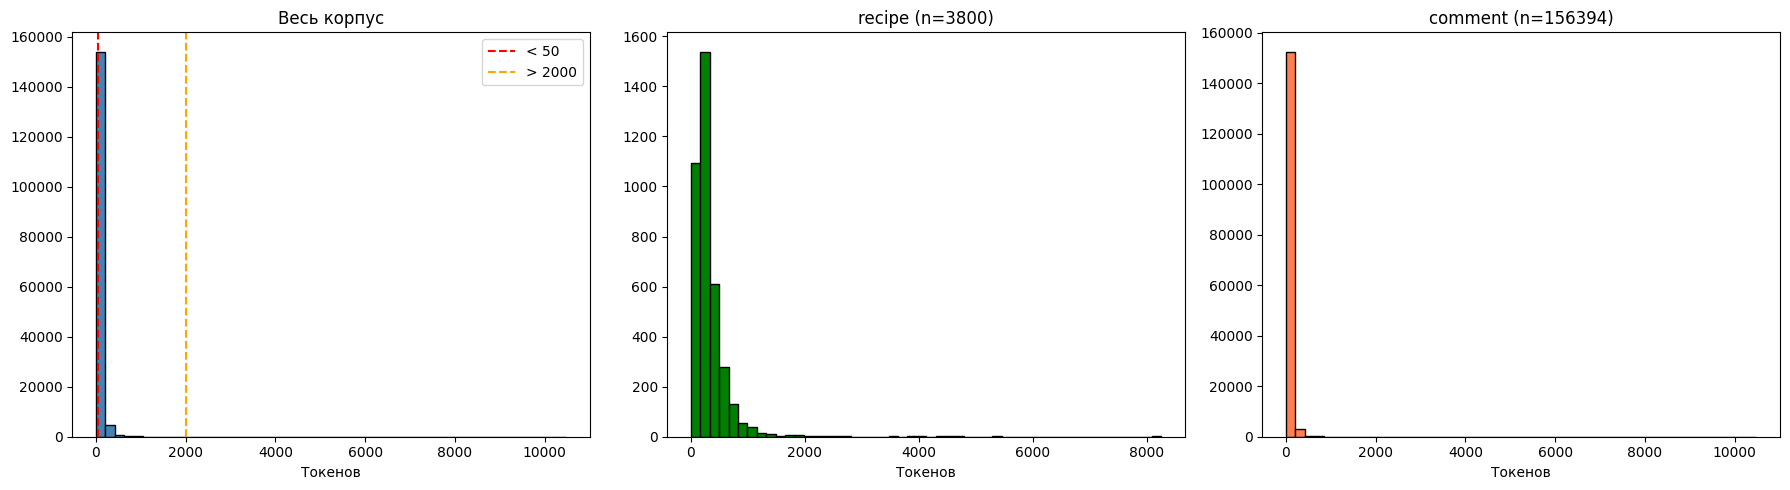

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df['token_count'], bins=50, color='steelblue', edgecolor='black')
axes[0].axvline(50, color='red', linestyle='--', label='< 50')
axes[0].axvline(2000, color='orange', linestyle='--', label='> 2000')
axes[0].set_title('Весь корпус')
axes[0].set_xlabel('Токенов')
axes[0].legend()

for i, t in enumerate(['recipe', 'comment']):
    subset = df[df['type'] == t]['token_count']
    axes[i+1].hist(subset, bins=50, color='green' if t == 'recipe' else 'coral', edgecolor='black')
    axes[i+1].set_title(f'{t} (n={len(subset)})')
    axes[i+1].set_xlabel('Токенов')

plt.tight_layout()
plt.show()

На гистограмме у рецептов есть тяжелый хвост.

Посмотрим на "мусорные" токены.

In [25]:
import re

def trash_stats(text):
    if not isinstance(text, str):
        return {'emoji': 0, 'url': 0, 'digits': 0, 'special': 0, 'total': 0}

    emoji = len(re.findall(r'[\U0001F300-\U0001FAFF\U00002600-\U000027BF]', text))
    url = len(re.findall(r'https?://\S+|www\.\S+', text))
    digits = len(re.findall(r'\d', text))
    special = len(re.findall(r'[^\w\s]', text))

    return {'emoji': emoji, 'url': url, 'digits': digits, 'special': special, 'total': len(text)}

stats = df['text'].apply(trash_stats).apply(pd.Series)
df = pd.concat([df, stats], axis=1)

total_chars = df['total'].sum()
print(f"Всего символов: {total_chars:,}")
print(f"Эмодзи:         {df['emoji'].sum():,} ({df['emoji'].sum()/total_chars:.3%})")
print(f"URL:            {df['url'].sum():,} ({df['url'].sum()/total_chars:.3%})")
print(f"Цифры:          {df['digits'].sum():,} ({df['digits'].sum()/total_chars:.3%})")
print(f"Спецсимволы:    {df['special'].sum():,} ({df['special'].sum()/total_chars:.3%})")


for t in ['comment', 'recipe']:
    subset = df[df['type'] == t]
    total = subset['total'].sum()
    print(f"\n{t.upper()} (символов: {total:,}):")
    print(f"  Эмодзи:      {subset['emoji'].sum()/total:.3%}")
    print(f"  URL:         {subset['url'].sum()/total:.3%}")
    print(f"  Цифры:       {subset['digits'].sum()/total:.3%}")
    print(f"  Спецсимволы: {subset['special'].sum()/total:.3%}")

Всего символов: 44,574,318
Эмодзи:         2,442 (0.005%)
URL:            14,482 (0.032%)
Цифры:          355,739 (0.798%)
Спецсимволы:    2,563,592 (5.751%)

COMMENT (символов: 38,511,905):
  Эмодзи:      0.006%
  URL:         0.031%
  Цифры:       0.645%
  Спецсимволы: 5.929%

RECIPE (символов: 6,062,413):
  Эмодзи:      0.005%
  URL:         0.039%
  Цифры:       1.769%
  Спецсимволы: 4.624%


"Мусор" в токенах, преимущественно, за счет спецсимволов, но полностью мы их не сможем удалить (кавычки, тире дают структуру). Эмодзи и ссылок < 0.05%. В рецептах существенно больше цифр, но для нас это не "мусор" - а важная информация по количеству ингредиентов, удалять в рецептах их нельзя.

In [31]:
def get_minhash(text, num_perm=128):
    """MinHash по словам."""
    m = MinHash(num_perm=num_perm)
    for word in set(str(text).lower().split()):
        m.update(word.encode('utf-8'))
    return m

### Выберем 30000 документов
SAMPLE_SIZE = 30000
sample = df[df['text'].notna()].sample(n=min(SAMPLE_SIZE, len(df)), random_state=42).copy()

start = time.time()

minhashes = {}
for idx, text in sample['text'].items():
    minhashes[idx] = get_minhash(text)


lsh = MinHashLSH(threshold=0.8, num_perm=128)
for idx, m in minhashes.items():
    lsh.insert(idx, m)

duplicates = {}
for idx, m in minhashes.items():
    result = [r for r in lsh.query(m) if r != idx]
    if result:
        duplicates[idx] = result

print(f"Документов с near-duplicates: {len(duplicates)}")
print(f"Всего пар: {sum(len(v) for v in duplicates.values()) // 2}")
print(f"Доля от выборки: {len(duplicates)/len(sample):.1%}")

if duplicates:
    dup_types = sample.loc[list(duplicates.keys()), 'type'].value_counts()
    print("\n=== ПО ТИПАМ ===")
    print(dup_types)


    for t in ['comment', 'recipe']:
        total_t = (sample['type'] == t).sum()
        dup_t = (sample.loc[list(duplicates.keys()), 'type'] == t).sum()
        print(f"{t}: {dup_t}/{total_t} ({dup_t/total_t:.1%})")

print("\n=== ПРИМЕРЫ NEAR-DUPLICATES ===")
for i, (idx, dups) in enumerate(list(duplicates.items())[:5]):
    print(f"\n--- Пара {i+1} ---")
    print(f"Doc {idx} ({sample.loc[idx, 'type']}): {sample.loc[idx, 'text'][:150]}...")
    print(f"Похож на Doc {dups[0]} ({sample.loc[dups[0], 'type']}): {sample.loc[dups[0], 'text'][:150]}...")

Документов с near-duplicates: 5156
Всего пар: 2728
Доля от выборки: 17.2%

=== ПО ТИПАМ ===
type
comment    5156
Name: count, dtype: int64
comment: 5156/29298 (17.6%)
recipe: 0/702 (0.0%)

=== ПРИМЕРЫ NEAR-DUPLICATES ===

--- Пара 1 ---
Doc 131503 (comment): Очень интересно и необычно!!!!! Шоколадный кулич!!!!...
Похож на Doc 131517 (comment): Очень интересно и необычно!!!!! Шоколадный кулич!!!!...

--- Пара 2 ---
Doc 106042 (comment): Очень интересный рецептик и хитрый способ накормить семейство такой полезной пшенкой Скажите, а 1-2 дня в холодильнике тесто перенесет без ущерба вкус...
Похож на Doc 106027 (comment): Очень интересный рецептик и хитрый способ накормить семейство такой полезной пшенкой Скажите, а 1-2 дня в холодильнике тесто перенесет без ущерба вкус...

--- Пара 3 ---
Doc 48069 (comment): Katjuwka писал(а): Почти каждое утро я ем именно ЭТУ кашу!!! Катюша, значит мы каждое утро едим практически одинаковый завтрак! Katjuwka писал(а): Олю...
Похож на Doc 48054 (comment): 

По рассматриваемой выборке дубликаты нашлись для комментариев в 17.6% случаев.

In [32]:
# Дубликаты по topic_url + text
dups = df.duplicated(subset=['topic_url', 'text'], keep=False)
print(f"Строк с дубликатами: {dups.sum()} ({dups.sum()/len(df):.1%})")

# Уникальных комбинаций
unique = df.drop_duplicates(subset=['topic_url', 'text'])
print(f"Было: {len(df)}, стало: {len(unique)}")

Строк с дубликатами: 113083 (70.6%)
Было: 160194, стало: 98621


In [33]:
text_groups = df.groupby('text').agg({
    'topic_url': 'nunique',
    'author': 'nunique'
}).rename(columns={'topic_url': 'n_topics', 'author': 'n_authors'})

print("Текстов в 1 теме:", (text_groups['n_topics'] == 1).sum())
print("Текстов в 2+ темах:", (text_groups['n_topics'] > 1).sum())

multi = text_groups[text_groups['n_topics'] > 1]
print(f"\nВсего текстов в 2+ темах: {len(multi)}")
print(multi.head(10))

Текстов в 1 теме: 98466
Текстов в 2+ темах: 67

Всего текстов в 2+ темах: 67
                                                                                                                                                                                                           n_topics  \
text                                                                                                                                                                                                                  
[URL=http://[censored smayliki]/smilie-949906119.html] [/URL]                                                                                                                                                     2   
omilo Олечка, спасибо, вкусно!                                                                                                                                                                                    2   
photo2011 Наташенька! Спасибо.                                 

In [34]:
dup_counts = df.groupby(['topic_url', 'text']).size()

dups = dup_counts[dup_counts >= 2].sort_values(ascending=False)

print(f"Всего пар с дубликатами: {len(dups)}")
print(f"\nТоп-10 самых частых:")
print(dups.head(10))

Всего пар с дубликатами: 51510

Топ-10 самых частых:
topic_url                                 text                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [48]:
url = 'https://forum.say7.info/topic13007.html'
text = 'Олечка,я тоже пришла с отчётиком!'

matches = df[(df['topic_url'] == url) & (df['text'].str.contains(text))]
matches

,topic_url,topic_title,author,real_name,date,text
32227,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:43,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32228,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:44,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32229,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:44,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32242,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:43,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32243,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:44,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32244,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:44,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32256,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:43,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32257,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:44,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"
32258,https://forum.say7.info/topic13007.html,«Мадам скумбрия»,Ким 5+,Елена,28 Окт 2009 20:44,"Олечка,я тоже пришла с отчётиком!Рыбка,ну ооооочень вкусная!!! Даже моя дочка, которая не любит рыбу, кушала с огромным удовольствием!"


На сайте данный комментарий встречается 3 раза. Добавим post_id в парсер. Для экономии времени перезапуск парсера не проводился, так как требует 6ч на пересчет. Удалим дубликаты по всем полям в датафрейме.

In [ ]:
import requests
from bs4 import BeautifulSoup
import time
import csv
import re
import os
from google.colab import drive

drive.mount('/content/drive')
OUTPUT_DIR = '/content/drive/MyDrive/Agents_Course/say7_forum_corpus'
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_FILE = os.path.join(OUTPUT_DIR, 'say7_forum_posts.csv')

BASE_URL = "https://forum.say7.info"
HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                  '(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
}

FORUM_URLS = [
    'https://forum.say7.info/forum66.html', 'https://forum.say7.info/forum64.html',
    "https://forum.say7.info/forum65.html", 'https://forum.say7.info/forum74.html',
    'https://forum.say7.info/forum76.html', 'https://forum.say7.info/forum70.html',
    'https://forum.say7.info/forum77.html', 'https://forum.say7.info/forum67.html',
    'https://forum.say7.info/forum68.html', 'https://forum.say7.info/forum73.html',
    'https://forum.say7.info/forum69.html', 'https://forum.say7.info/forum75.html',
    'https://forum.say7.info/forum111.html', 'https://forum.say7.info/forum71.html',
    'https://forum.say7.info/forum78.html', 'https://forum.say7.info/forum79.html',
    'https://forum.say7.info/forum45.html', 'https://forum.say7.info/forum50.html',
    'https://forum.say7.info/forum98.html'
]

MAX_TOPICS_PER_FORUM = 200
MAX_TOPIC_PAGES = 3
MAX_FORUM_PAGES = 10
SLEEP = 1.0

FIELDNAMES = ['post_id', 'topic_url', 'topic_title', 'author', 'real_name', 'date', 'text']


def fix_url(href):
    if not href:
        return None
    if href.startswith('http'):
        return href
    return BASE_URL + '/' + href.lstrip('/')


def clean_text(text):
    if not text:
        return ""
    return re.sub(r'\s+', ' ', text).strip()


def safe_text(text):
    if not isinstance(text, str):
        return text
    return text.encode('utf-8', 'ignore').decode('utf-8', 'ignore')


def load_seen_ids():
    seen = set()
    if os.path.exists(OUTPUT_FILE):
        with open(OUTPUT_FILE, 'r', encoding='utf-8') as f:
            reader = csv.DictReader(f)
            for row in reader:
                if row.get('post_id'):
                    seen.add(row['post_id'])
    return seen


def get_topic_links(forum_url, max_pages=MAX_FORUM_PAGES):
    topic_links = {}
    for page in range(1, max_pages + 1):
        url = forum_url if page == 1 else f"{forum_url}?start={(page-1)*25}"
        try:
            resp = requests.get(url, headers=HEADERS, timeout=15)
            resp.encoding = 'windows-1251'
            resp.raise_for_status()
            soup = BeautifulSoup(resp.text, 'html.parser')

            links = soup.select('a.topictitle')
            found = 0
            for link in links:
                href = link.get('href')
                title = clean_text(link.get_text())
                if href and re.search(r'topic\d+', href):
                    full = fix_url(href)
                    if full and full not in topic_links:
                        topic_links[full] = title
                        found += 1
            print(f"  Раздел, стр. {page}: {found} новых тем")
            time.sleep(SLEEP)
        except Exception as e:
            print(f"  Ошибка: {e}")
            break
    return topic_links


def parse_topic_to_writer(topic_url, topic_title, writer, seen_ids, max_pages=MAX_TOPIC_PAGES):
    written = 0
    for page in range(1, max_pages + 1):
        url = topic_url if page == 1 else f"{topic_url}?start={(page-1)*10}"
        try:
            resp = requests.get(url, headers=HEADERS, timeout=15)
            resp.encoding = 'windows-1251'
            resp.raise_for_status()
            soup = BeautifulSoup(resp.text, 'html.parser')

            rows = soup.select('tr.rdmdt')
            if not rows:
                break

            current_author = ""
            current_realname = ""
            current_date = ""

            for row in rows:
                nick_el = row.select_one('.pdtnm.nickname')
                if nick_el:
                    current_author = clean_text(nick_el.get_text())

                realname_el = row.select_one('.pdtav.photo div')
                if realname_el:
                    current_realname = clean_text(realname_el.get_text())

                date_el = row.select_one('.ipdata.taright')
                if date_el:
                    current_date = clean_text(date_el.get_text())

                postbody = row.select_one('div.postbody:not(.signature)')
                if not postbody:
                    continue

                post_id = postbody.get('id')
                if not post_id:
                    continue
                if post_id in seen_ids:
                    continue

                for sig in postbody.select('.signature'):
                    sig.decompose()

                text = clean_text(postbody.get_text(separator=' ', strip=True))
                if len(text) < 20:
                    continue

                writer.writerow({
                    'post_id': safe_text(post_id),
                    'topic_url': safe_text(topic_url),
                    'topic_title': safe_text(topic_title),
                    'author': safe_text(current_author),
                    'real_name': safe_text(current_realname),
                    'date': safe_text(current_date),
                    'text': safe_text(text),
                })
                seen_ids.add(post_id)
                written += 1

            time.sleep(SLEEP)
        except Exception as e:
            print(f"    Ошибка на стр. {page}: {e}")
            break
    return written


def main():
    file_exists = os.path.exists(OUTPUT_FILE)

    seen_ids = load_seen_ids()
    if seen_ids:
        print(f"{len(seen_ids)}")

    with open(OUTPUT_FILE, 'a', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=FIELDNAMES)
        if not file_exists:
            writer.writeheader()

        total = 0
        for forum_url in FORUM_URLS:
            print(f"\n=== {forum_url} ===")
            topics = get_topic_links(forum_url)
            print(f"  Всего тем: {len(topics)}")

            for i, (topic_url, topic_title) in enumerate(list(topics.items())[:MAX_TOPICS_PER_FORUM]):
                print(f"\n  [{i+1}] {topic_title[:60]}")
                written = parse_topic_to_writer(topic_url, topic_title, writer, seen_ids)
                f.flush()
                os.fsync(f.fileno())
                total += written
                print(f"{written} (всего {total})")

    print(f"\n {OUTPUT_FILE}")


if __name__ == "__main__":
    main()

In [70]:
df = df.drop(columns = 'tokens_list')

In [71]:
df_2 = df.drop_duplicates()

In [72]:
df_2['type'].value_counts()

,count
type,
comment,94863
recipe,3800


Видим, что комментариев стало меньше на 61.5 тыс. шт.

In [73]:
df_2.groupby('type')['token_count'].describe().astype(int)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
comment,94863,51,75,2,17,33,63,10485
recipe,3800,319,331,4,158,245,376,8262


Видим, что распределение длин токенов практически не изменилось после дедубликации. Сохраним на диск.

In [86]:
def tokenize(text):
    if not isinstance(text, str):
        return []
    return re.findall(r'\w+|[^\w\s]', text)

df_2['tokens_list'] = df_2['text'].apply(tokenize)

/tmp/ipykernel_919/1356736567.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2['tokens_list'] = df_2['text'].apply(tokenize)


In [87]:
df_2.to_csv('say7_forum_posts_clean.csv', index = False)

In [89]:
import shutil
shutil.copy('say7_forum_posts_clean.csv', '/content/drive/MyDrive/Agents_Course/say7_forum_posts_clean.csv')

'/content/drive/MyDrive/Agents_Course/say7_forum_posts_clean.csv'

Ссылка на датсет: https://drive.google.com/file/d/1ix4CgJU-BMXRqv-MmpEzA-eZTbbAOR2K/view?usp=sharing

# Золотой датасет

**Модель:** DeepSeek (chat.deepseek - web)

**Температура:** по умолчанию  

**Промпт:**

Ты — эксперт по RAG-оценке. Корпус: форум say7.info
(рецепты + комментарии).

Темы корпуса: салаты, супы, вторые блюда, выпечка,
каши, специи, корейская кухня, закарпатская кухня,
аэрогриль, пароварка.

Сгенерируй 40 вопросов:
- 12 фактических (ответ в одном чанке)
- 12 составных (ответ требует 2+ чанков)
- 8 абстрактных (о теме/тенденции)
- 8 негативных (ответа в корпусе нет)

Требования:
- Вопросы на русском, разговорные и формальные.
- ~15% с опечатками (для проверки устойчивости).
- Имена собственные в разных формах.
- Очень короткие («Что такое X?») и развёрнутые.

Формат вывода — таблица:
| № | Вопрос | Тип | Примерный ответ | Ключевые слова |


In [81]:
data = [
    # --- ФАКТИЧЕСКИЕ (12) ---
    (1, "Что такое закарпатский бограч?", "Фактический",
     "Бограч — густой венгерско-закарпатский суп-гуляш с мясом, паприкой и овощами",
     "Ответ содержится в одном чанке: определение бограча как закарпатского супа-гуляша. Проверяет извлечение точного факта-определения.",
     "бограч, закарпатский суп, паприка"),
    (2, "Как приготовить салат «Мимоза»?", "Фактический",
     "Слоёный салат с рыбой, картофелем, морковью, яйцами и майонезом",
     "Один чанк с рецептом: состав слоёв и ингредиенты. Проверяет извлечение пошагового факта.",
     "мимоза, салат, рыба, слои"),
    (3, "Что такое аэрогриль и для чего он нужен?", "Фактический",
     "Прибор для приготовления блюд горячим воздухом, аналог конвекционной печи",
     "Один чанк-описание прибора. Проверяет определение и назначение техники.",
     "аэрогриль, горячий воздух, приготовление"),
    (4, "Как заваривать куриный бульон для супа?", "Фактический",
     "Курицу варят 1–1,5 часа на медленном огне, снимая пену, с луком и морковью",
     "Один чанк с технологией варки бульона. Проверяет время, режим и добавки.",
     "куриный бульон, суп, варка"),
    (5, "Что такое кимчи по-корейски?", "Фактический",
     "Кимчи — квашеная пекинская капуста с острым перцем, чесноком и специями",
     "Один чанк-определение корейского блюда. Проверяет знание ключевого ингредиента и способа приготовления.",
     "кимчи, корейская кухня, капуста"),
    (6, "Сколько варить гречку на воде?", "Фактический",
     "Гречку варят 15–20 минут на медленном огне под крышкой",
     "ОПЕЧАТКА: «гречку» (разговорная форма). Один чанк с временем варки каши.",
     "гречка, каша, варка"),
    (7, "Какой рис нужен для плова?", "Фактический",
     "Для плова берут длиннозёрный рис: девзира, басмати или жасмин",
     "Один чанк со списком сортов риса. Проверяет конкретные названия (девзира, басмати).",
     "плов, рис, девзира"),
    (8, "Что добавляют в борщ для цвета?", "Фактический",
     "Свёклу, иногда с уксусом или лимонным соком для сохранения цвета",
     "Один чанк о приёме сохранения цвета. Проверяет факт про свёклу и кислоту.",
     "борщ, свёкла, цвет"),
    (9, "Как готовить на пароварке овощи?", "Фактический",
     "Овощи закладывают в корзину, готовят 10–25 минут в зависимости от вида",
     "ОПЕЧАТКА: «пароварке». Один чанк с временем и способом приготовления.",
     "пароварка, овощи, пар"),
    (10, "Какие специи кладут в харчо?", "Фактический",
     "Хмели-сунели, кинза, чеснок, острый перец, лавровый лист",
     "Один чанк со списком специй. Проверяет извлечение перечня ингредиентов.",
     "харчо, специи, хмели-сунели"),
    (11, "Что такое паста том-ям?", "Фактический",
     "Тайская паста из чили, лемонграсса, галангала и креветок для супа том-ям",
     "Один чанк-определение пасты. Проверяет состав и назначение продукта.",
     "том-ям, паста, тайская кухня"),
    (12, "Как испечь шарлотку с яблоками?", "Фактический",
     "Яблоки заливают тестом из яиц, сахара и муки, пекут 30–40 минут при 180°C",
     "Один чанк с рецептом и температурой. Проверяет пошаговый факт выпечки.",
     "шарлотка, яблоки, выпечка"),

    # --- СОСТАВНЫЕ (12) ---
    (13, "Чем отличается закарпатский борщ от обычного украинского?", "Составной",
     "Закарпатский — с грибами, черносливом, фасолью; обычный — со свёклой и капустой",
     "Нужны 2+ чанка: рецепт закарпатского борща и рецепт обычного — сравнение ингредиентов.",
     "борщ, закарпатский, отличия"),
    (14, "Как приготовить кимчи и сколько его хранить?", "Составной",
     "Капусту солят, заправляют пастой из перца и чеснока, хранят в холоде 1–2 недели",
     "ОПЕЧАТКА: «кимчи». Нужны 2 чанка: рецепт закваски + условия/сроки хранения.",
     "кимчи, хранение, закваска"),
    (15, "Что приготовить в аэрогриле из курицы и картошки?", "Составной",
     "Курицу маринуют со специями, картофель режут, запекают вместе 40–50 минут",
     "2+ чанка: рецепт курицы в аэрогриле + рецепт картофеля; ответ объединяет оба.",
     "аэрогриль, курица, картошка"),
    (16, "Как сварить суп из курицы и сделать к нему заправку?", "Составной",
     "Варят бульон, добавляют картофель, морковь, лук; заправляют зажаркой",
     "2 чанка: рецепт куриного супа + рецепт зажарки/заправки.",
     "суп, курица, зажарка"),
    (17, "Какие блюда корейской кухни можно сделать из капусты и моркови?", "Составной",
     "Кимчи, салат из моркови по-корейски, ким-чи с редькой",
     "2+ чанка: рецепт кимчи + рецепт моркови по-корейски; ответ — объединение.",
     "корейская кухня, капуста, морковь"),
    (18, "Как приготовить гречку с мясом на пароварке?", "Составной",
     "Гречку замачивают, мясо режут, готовят в пароварке слоями 40 минут",
     "ОПЕЧАТКА: «пароварке». 2 чанка: рецепт гречки + рецепт мяса на пару.",
     "гречка, мясо, пароварка"),
    (19, "Чем отличаются специи для плова и для харчо?", "Составной",
     "Для плова — зира, барбарис, куркума; для харчо — хмели-сунели, кинза, чеснок",
     "2 чанка: специи для плова + специи для харчо; ответ — сравнение.",
     "плов, харчо, специи"),
    (20, "Как испечь пирог с яблоками и приготовить к нему крем?", "Составной",
     "Шарлотка или песочный пирог; крем — сметанный или заварной",
     "2 чанка: рецепт пирога + рецепт крема; ответ объединяет выпечку и крем.",
     "пирог, яблоки, крем"),
    (21, "Что общего у закарпатской и корейской кухни в say7?", "Составной",
     "Обе используют острое, квашение, много овощей и специй",
     "2+ чанка: обзор закарпатской кухни + обзор корейской; ответ — синтез общего.",
     "закарпатская, корейская, общее"),
    (22, "Как приготовить борщ и кимчи на одной кухне?", "Составной",
     "Борщ варят на плите, кимчи квасят отдельно в банке",
     "ОПЕЧАТКА: «кимчи». 2 чанка: рецепт борща + рецепт кимчи; ответ — совместное приготовление.",
     "борщ, кимчи, кухня"),
    (23, "Какие супы и вторые блюда популярны на форуме?", "Составной",
     "Борщ, харчо, том-ям; плов, гуляш, запеканки",
     "2+ чанка: раздел «супы» + раздел «вторые блюда»; ответ агрегирует популярное.",
     "супы, вторые, форум"),
    (24, "Как использовать аэрогриль и пароварку для выпечки?", "Составной",
     "В аэрогриле — кексы, в пароварке — диетические бисквиты",
     "2 чанка: выпечка в аэрогриле + выпечка в пароварке; ответ объединяет приборы.",
     "аэрогриль, пароварка, выпечка"),

    # --- АБСТРАКТНЫЕ (8) ---
    (25, "Какие тенденции в рецептах салатов на say7?", "Абстрактный",
     "Много слоёных салатов, с рыбой, курицей, корейской морковью",
     "Требует обобщения по множеству чанков раздела «салаты», а не одного факта.",
     "салаты, тенденции, форум"),
    (26, "Что чаще обсуждают: супы или выпечку?", "Абстрактный",
     "Супы обсуждают активнее: борщ, харчо, том-ям",
     "Требует оценки частоты/активности по корпусу, а не извлечения одного факта.",
     "обсуждения, супы, выпечка"),
    (27, "Как на форуме относятся к корейской кухне?", "Абстрактный",
     "Положительно, много рецептов кимчи, моркови, салатов",
     "Требует тональности/обобщения по разделу «корейская кухня».",
     "корейская, отношение, форум"),
    (28, "Какие темы самые популярные в разделе «вторые блюда»?", "Абстрактный",
     "Плов, гуляш, запечённое мясо, картофель",
     "Требует агрегации по разделу «вторые блюда», выделения частотных тем.",
     "вторые, популярные, темы"),
    (29, "Есть ли на форуме вегетарианские рецепты?", "Абстрактный",
     "Да, овощные супы, салаты, блюда на пароварке",
     "Требует обзорного поиска по всему корпусу, а не одного чанка.",
     "вегетарианские, рецепты"),
    (30, "Как меняются рецепты со временем на say7?", "Абстрактный",
     "Появляются блюда для аэрогриля и пароварки, упрощаются",
     "Требует анализа динамики тем по корпусу (временной/тематический тренд).",
     "эволюция, рецепты, время"),
    (31, "Что важнее в закарпатской кухне: мясо или грибы?", "Абстрактный",
     "Оба важны: грибы в борще, мясо в бограче",
     "Оценочный вопрос о значимости; требует синтеза по нескольким рецептам.",
     "закарпатская, мясо, грибы"),
    (32, "Какие специи чаще всего упоминают на форуме?", "Абстрактный",
     "Паприка, хмели-сунели, зира, чеснок, перец",
     "Требует частотного анализа упоминаний специй по всему корпусу.",
     "специи, частота, форум"),

    # --- НЕГАТИВНЫЕ (8) ---
    (33, "Как приготовить пиццу в аэрогриле?", "Негативный",
     "В корпусе нет ответа",
     "Аэрогриль в корпусе есть, но пицца в нём не раскрыта: обсуждаются курица, картофель, овощи, кексы. Комбинация «аэрогриль + пицца» отсутствует.",
     "пицца, аэрогриль"),
    (34, "Есть ли рецепт суши на say7?", "Негативный",
     "В корпусе нет ответа",
     "В темах есть «корейская кухня», но суши — японская кухня и в списке тем отсутствует. Рецептов суши/роллов нет.",
     "суши, рецепт"),
    (35, "Как сделать сыр в домашних условиях?", "Негативный",
     "В корпусе нет ответа",
     "Сыроварение не входит ни в одну заявленную тему (салаты, супы, вторые, выпечка, каши, специи, корейская, закарпатская, аэрогриль, пароварка). Домашний сыр не обсуждается.",
     "сыр, домашний"),
    (36, "Какие рецепты для мультиварки есть на say7?", "Негативный",
     "В корпусе нет ответа",
     "Мультиварка не указана среди тем корпуса. Есть аэрогриль и пароварка — другие приборы; переносить их рецепты нельзя.",
     "мультиварка, рецепты"),
    (37, "Как приготовить фондю?", "Негативный",
     "В корпусе нет ответа",
     "Фондю — отдельная кулинарная тема (швейцарская/французская), в списке тем отсутствует. Ни в салатах, ни в супах, ни во вторых блюдах не упоминается.",
     "фондю, рецепт"),
    (38, "Есть ли рецепты без глютена?", "Негативный",
     "В корпусе нет ответа",
     "Безглютеновая диета/маркировка в корпусе не выделяется. Отдельной категории «без глютена» нет, рецепты не помечены.",
     "без глютена, рецепты"),
    (39, "Как коптить рыбу на даче?", "Негативный",
     "В корпусе нет ответа",
     "Копчение как способ приготовления в темах корпуса не заявлено. Есть аэрогриль и пароварка — иные технологии; рыба в этих темах тоже не раскрыта.",
     "копчение, рыба"),
    (40, "Какие блюда для аэрогриля с рыбой?", "Негативный",
     "В корпусе нет ответа",
     "Аэрогриль в корпусе есть, но рыба в нём не обсуждается: рецепты про курицу, картофель, овощи, выпечку. Комбинация «аэрогриль + рыба» отсутствует.",
     "аэрогриль, рыба"),
]

gold = pd.DataFrame(data, columns=[
    "№", "Вопрос", "Тип", "Gold-ответ", "Комментарий", "Ключевые слова"
])

print("Всего вопросов:", len(gold))
print(gold["Тип"].value_counts())
print("\nОпечатки:", gold["Комментарий"].str.contains("ОПЕЧАТКА").sum())


gold.to_csv("say7_rag_gold.csv", index=False, encoding="utf-8-sig")
gold.to_json("say7_rag_gold.json", orient="records", force_ascii=False, indent=2)
gold.to_excel("say7_rag_gold.xlsx", index=False)

gold

Всего вопросов: 40
Тип
Фактический    12
Составной      12
Абстрактный     8
Негативный      8
Name: count, dtype: int64

Опечатки: 5


,№,Вопрос,Тип,Gold-ответ,Комментарий,Ключевые слова
0,1,Что такое закарпатский бограч?,Фактический,"Бограч — густой венгерско-закарпатский суп-гуляш с мясом, паприкой и овощами",Ответ содержится в одном чанке: определение бограча как закарпатского супа-гуляша. Проверяет извлечение точного факта-определения.,"бограч, закарпатский суп, паприка"
1,2,Как приготовить салат «Мимоза»?,Фактический,"Слоёный салат с рыбой, картофелем, морковью, яйцами и майонезом",Один чанк с рецептом: состав слоёв и ингредиенты. Проверяет извлечение пошагового факта.,"мимоза, салат, рыба, слои"
2,3,Что такое аэрогриль и для чего он нужен?,Фактический,"Прибор для приготовления блюд горячим воздухом, аналог конвекционной печи",Один чанк-описание прибора. Проверяет определение и назначение техники.,"аэрогриль, горячий воздух, приготовление"
3,4,Как заваривать куриный бульон для супа?,Фактический,"Курицу варят 1–1,5 часа на медленном огне, снимая пену, с луком и морковью","Один чанк с технологией варки бульона. Проверяет время, режим и добавки.","куриный бульон, суп, варка"
4,5,Что такое кимчи по-корейски?,Фактический,"Кимчи — квашеная пекинская капуста с острым перцем, чесноком и специями",Один чанк-определение корейского блюда. Проверяет знание ключевого ингредиента и способа приготовления.,"кимчи, корейская кухня, капуста"
5,6,Сколько варить гречку на воде?,Фактический,Гречку варят 15–20 минут на медленном огне под крышкой,ОПЕЧАТКА: «гречку» (разговорная форма). Один чанк с временем варки каши.,"гречка, каша, варка"
6,7,Какой рис нужен для плова?,Фактический,"Для плова берут длиннозёрный рис: девзира, басмати или жасмин","Один чанк со списком сортов риса. Проверяет конкретные названия (девзира, басмати).","плов, рис, девзира"
7,8,Что добавляют в борщ для цвета?,Фактический,"Свёклу, иногда с уксусом или лимонным соком для сохранения цвета",Один чанк о приёме сохранения цвета. Проверяет факт про свёклу и кислоту.,"борщ, свёкла, цвет"
8,9,Как готовить на пароварке овощи?,Фактический,"Овощи закладывают в корзину, готовят 10–25 минут в зависимости от вида",ОПЕЧАТКА: «пароварке». Один чанк с временем и способом приготовления.,"пароварка, овощи, пар"
9,10,Какие специи кладут в харчо?,Фактический,"Хмели-сунели, кинза, чеснок, острый перец, лавровый лист",Один чанк со списком специй. Проверяет извлечение перечня ингредиентов.,"харчо, специи, хмели-сунели"


In [83]:
rejected = pd.DataFrame({
    'question': [
        'Сколько соли в салате?',
        'Какой рецепт самый популярный?',
        'Что приготовила Алена на Новый год в 2025?',
        'Как приготовить вино?'
    ],
    'reason': [
        'Слишком общий, ответа нет в корпусе',
        'Субъективно, нет объективного ответа',
        'Слишком узко, привязано к конкретному пользователю',
        'Тема алкогольных напитков не рассматривалась'
    ],
})
rejected.to_csv('gold_rejected.csv', index=False, encoding='utf-8')
rejected

,question,reason
0,Сколько соли в салате?,"Слишком общий, ответа нет в корпусе"
1,Какой рецепт самый популярный?,"Субъективно, нет объективного ответа"
2,Что приготовила Алена на Новый год в 2025?,"Слишком узко, привязано к конкретному пользователю"
3,Как приготовить вино?,Тема алкогольных напитков не рассматривалась


#Разделение на validation и test


In [85]:
import numpy as np
np.random.seed(42)

val_idx, test_idx = [], []
for qtype in gold['Тип'].unique():
    subset = gold[gold['Тип'] == qtype]
    n_val = int(len(subset) * 0.7)
    val_idx.extend(subset.index[:n_val])
    test_idx.extend(subset.index[n_val:])

gold_val = gold.loc[val_idx].reset_index(drop=True)
gold_test = gold.loc[test_idx].reset_index(drop=True)

print(f"Validation: {len(gold_val)}")
print(f"Test: {len(gold_test)}")
print(f"Val: {gold_val['Тип'].value_counts().to_dict()}")
print(f"Test: {gold_test['Тип'].value_counts().to_dict()}")

gold_val.to_csv('gold_val.csv', index=False, encoding='utf-8')
gold_test.to_csv('gold_test.csv', index=False, encoding='utf-8')

Validation: 26
Test: 14
Val: {'Фактический': 8, 'Составной': 8, 'Абстрактный': 5, 'Негативный': 5}
Test: {'Фактический': 4, 'Составной': 4, 'Абстрактный': 3, 'Негативный': 3}
